# 07 · Avaliação fora do tempo: novo modelo vs score atual

**Primeiro e único** uso do período de teste (11/04–21/04, 41,5 mil transações).

**Pergunta:** o novo modelo é melhor que o score em produção? Quanto, com que confiança, e onde?

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
from fraude.inferencia import ModeloFraude

In [2]:
base = dados.carregar_base()
teste = base[base["particao"] == "teste"].reset_index(drop=True)
artefato = ModeloFraude.carregar(cfg.ARQUIVO_MODELO)
print(artefato.metadados["versao"], "| treinado com", artefato.metadados["periodo_treino"])

teste["p_bruta"] = artefato.score_bruto(teste)
teste["p_modelo"] = artefato.probabilidade(teste)
teste[["fecha", "monto", "score", "fraude", "p_bruta", "p_modelo"]].to_parquet(cfg.ARQUIVO_PRED_TESTE, index=False)
y = teste["fraude"]
print(f"Teste: {len(teste):,} transações | {y.sum():,} fraudes ({y.mean():.2%})")

fraude-lgbm-v1 | treinado com ['2020-03-08 00:02:15', '2020-04-10 23:59:43']


Teste: 41,534 transações | 1,854 fraudes (4.46%)


## 1. Métricas de discriminação lado a lado

In [3]:
comp = pd.concat([
    metricas.resumo(y, teste["score"], teste["monto"], nome="Score atual"),
    metricas.resumo(y, teste["p_modelo"], teste["monto"], nome="Novo modelo"),
], axis=1)
comp["ganho absoluto"] = comp["Novo modelo"] - comp["Score atual"]
comp["ganho relativo"] = comp["Novo modelo"] / comp["Score atual"] - 1
comp.style.format({"Score atual": "{:.3f}", "Novo modelo": "{:.3f}", "ganho absoluto": "{:+.3f}",
                   "ganho relativo": "{:+.0%}"})

,Score atual,Novo modelo,ganho absoluto,ganho relativo
ROC AUC,0.726,0.851,+0.125,+17%
PR AUC (AP),0.227,0.368,+0.141,+62%
KS,0.453,0.546,+0.092,+20%
Recall @ FPR 1%,0.158,0.252,+0.094,+60%
Recall @ FPR 5%,0.418,0.478,+0.060,+14%
Recall @ FPR 10%,0.527,0.602,+0.075,+14%
Recall R$ @ FPR 5%,0.441,0.626,+0.185,+42%


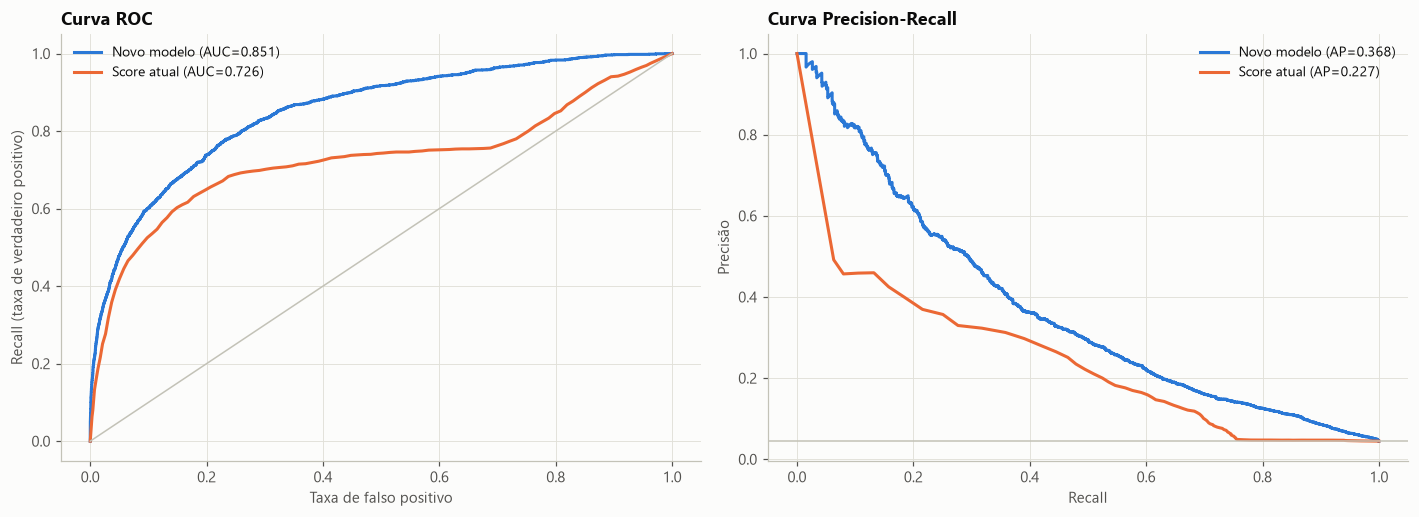

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
gr.curvas_roc_pr(y, {"Novo modelo": teste["p_modelo"], "Score atual": teste["score"]}, axes=axes)
plt.tight_layout()

### A diferença é estatisticamente robusta?
*Bootstrap* pareado: reamostramos as transações do teste 500 vezes e recalculamos a diferença entre
os modelos **na mesma amostra**.

In [5]:
ic = pd.DataFrame({
    "ROC AUC": metricas.bootstrap_diferenca(y, teste["p_modelo"], teste["score"], roc_auc_score),
    "PR AUC": metricas.bootstrap_diferenca(y, teste["p_modelo"], teste["score"], average_precision_score),
}).T
ic

,diferenca,ic95_inf,ic95_sup,p_valor (dif<=0)
ROC AUC,0.1247,0.1091,0.1400,0.0000
PR AUC,0.1409,0.1179,0.1625,0.0000


O intervalo de 95% da diferença fica **inteiramente acima de zero** nas duas métricas, e em nenhuma
reamostragem o score atual empatou ou venceu. 

Portanto, a superioridade não é "ruído amostral".

## 2. Leitura de negócio: quanta fraude capturamos bloqueando x% das transações?

Para o negócio, a pergunta prática é: *se eu rejeitar as x% transações mais arriscadas, que fração
das fraudes (em quantidade e em R$) eu evito?*

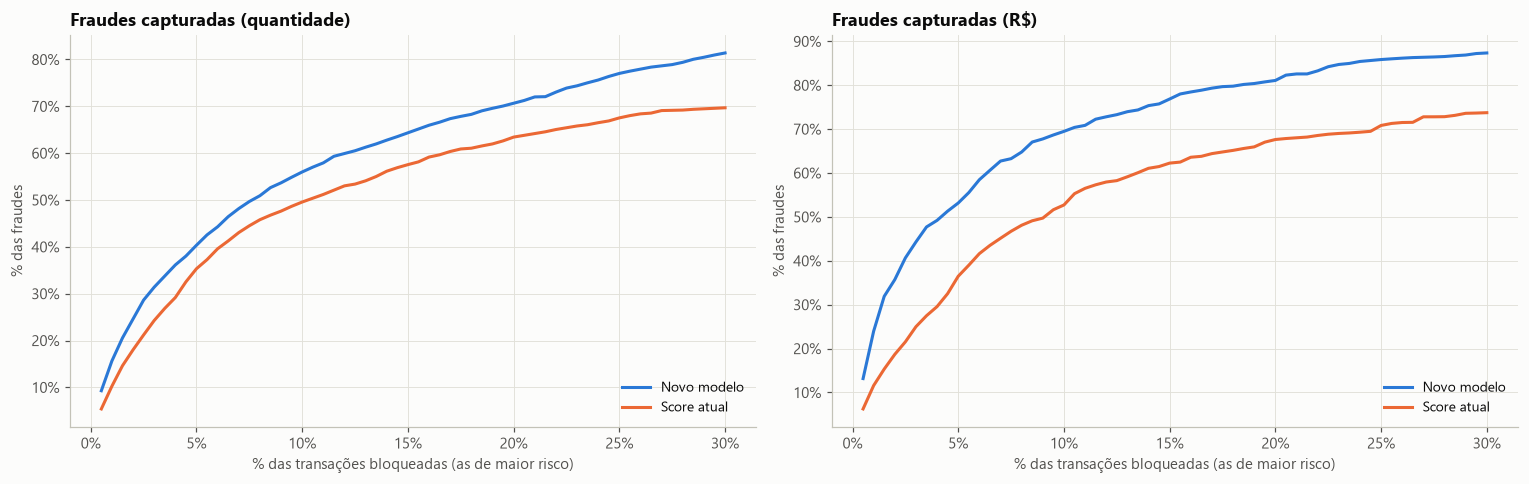

In [6]:
def captura(y, s, valor, taxas):
    ordem = np.argsort(-np.asarray(s))
    y_o, v_o = np.asarray(y)[ordem], np.asarray(valor)[ordem]
    out = []
    for t in taxas:
        k = int(round(t * len(y_o)))
        out.append({"taxa_bloqueio": t, "fraudes_capturadas": y_o[:k].sum() / y_o.sum(),
                    "valor_fraude_capturado": (v_o[:k] * y_o[:k]).sum() / (v_o * y_o).sum(),
                    "precisao": y_o[:k].mean()})
    return pd.DataFrame(out).set_index("taxa_bloqueio")

taxas = np.round(np.arange(0.005, 0.3001, 0.005), 3)
cap_novo = captura(y, teste["p_modelo"], teste["monto"], taxas)
cap_atual = captura(y, teste["score"] + np.random.default_rng(0).random(len(teste)) * 1e-6, teste["monto"], taxas)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, met, tit in zip(axes, ["fraudes_capturadas", "valor_fraude_capturado"],
                        ["Fraudes capturadas (quantidade)", "Fraudes capturadas (R$)"]):
    ax.plot(taxas, cap_novo[met], color=gr.AZUL, label="Novo modelo")
    ax.plot(taxas, cap_atual[met], color=gr.LARANJA, label="Score atual")
    ax.set(title=tit, xlabel="% das transações bloqueadas (as de maior risco)", ylabel="% das fraudes")
    gr.formatar_pct(ax); gr.formatar_pct(ax, "x")
    ax.legend(loc="lower right")
plt.tight_layout()

pontos = [0.01, 0.02, 0.05, 0.10, 0.20]
tab = pd.concat({"Score atual": cap_atual.loc[pontos], "Novo modelo": cap_novo.loc[pontos]}, axis=1)
tab.index = [f"bloquear {p:.0%}" for p in pontos]
tab.style.format("{:.1%}")

Para a **mesma taxa de bloqueio**, o novo modelo captura mais fraude em toda a curva. O ganho é
**maior em valor (R$) do que em quantidade**:
- bloqueando **5%** das transações, a captura sobe de ~35% para ~40% das fraudes em quantidade, mas de
  **~37% para ~53% do valor fraudado**;
- no **topo do ranking** a diferença é ainda mais clara: bloqueando 1%, a precisão sobe de ~46% para
  **~70%**. Bloqueios muito seletivos (ou filas de revisão manual pequenas) passam a acertar muito mais.

> O modelo aprendeu que valores altos e produtos de revenda elevam o risco, então prioriza as fraudes mais caras

## 3. Onde o ganho acontece: a "faixa ignorada" do score atual

No notebook 02 vimos que ~21% das fraudes recebem score atual entre 0 e 25 e passam por qualquer
política de corte. O novo modelo consegue enxergá-las?

In [7]:
faixa = pd.cut(teste["score"], [-1, 25, 60, 80, 100], labels=["0–25 (zona cega)", "26–60", "61–80", "81–100"])
lim_novo = np.quantile(teste["p_modelo"], 0.90)   # novo modelo bloqueando 10% das transações
lim_atual = np.quantile(teste["score"], 0.90)     # score atual bloqueando ~10% das transações
fr = teste[y == 1].assign(faixa=faixa[y == 1])
zona = fr.groupby("faixa", observed=True).agg(
    fraudes=("fraude", "size"),
    capturadas_score_atual=("score", lambda s: (s >= lim_atual).mean()),
    capturadas_novo_modelo=("p_modelo", lambda p: (p >= lim_novo).mean()),
)
zona["%_das_fraudes"] = zona["fraudes"] / zona["fraudes"].sum()
zona.style.format({"capturadas_score_atual": "{:.1%}", "capturadas_novo_modelo": "{:.1%}", "%_das_fraudes": "{:.1%}"})

,fraudes,capturadas_score_atual,capturadas_novo_modelo,%_das_fraudes
faixa,,,,
0–25 (zona cega),441,0.0%,27.0%,23.8%
26–60,112,0.0%,25.9%,6.0%
61–80,308,0.0%,49.4%,16.6%
81–100,993,95.2%,74.3%,53.6%


Com a mesma taxa de bloqueio (10%), o score atual concentra todo o bloqueio na faixa 81–100 e **não
captura nenhuma** fraude abaixo dela. 

Já o novo modelo captura **~27% das fraudes** da "faixa ignorada", que no teste somam ~24% de todas as fraudes, e **metade das fraudes** da faixa 61–80**. 

Ou seja, ele captura menos que o atual na faixa 81–100 (74% contra 95%), mas no total recupera muito mais, porque redistribui o "orçamento" de bloqueios para onde o risco realmente está.

## 4. Estabilidade no período de teste

Dias em que o novo modelo supera o atual: 11 de 11


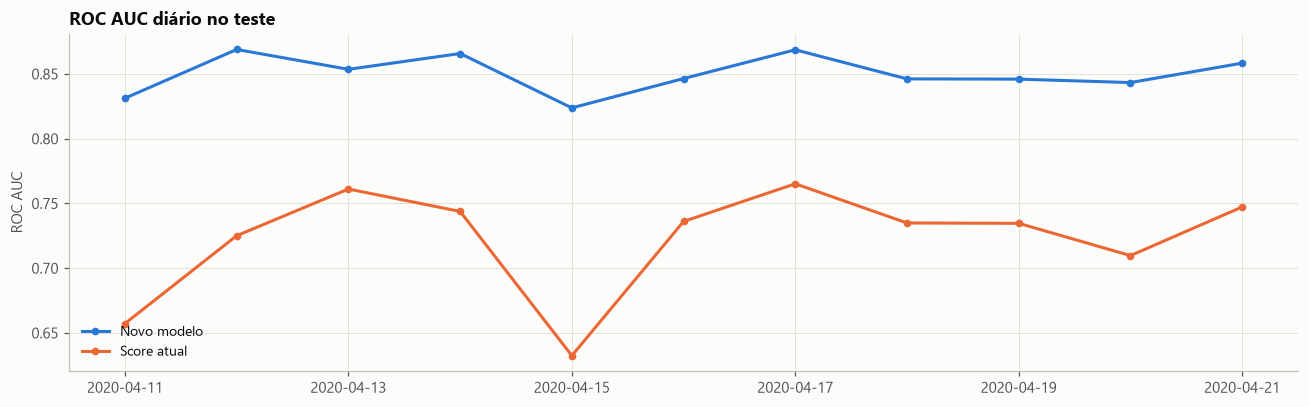

In [8]:
dia = teste["fecha"].dt.normalize()
diario = teste.groupby(dia).apply(lambda g: pd.Series({
    "Novo modelo": roc_auc_score(g["fraude"], g["p_modelo"]),
    "Score atual": roc_auc_score(g["fraude"], g["score"]),
}))
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(diario.index, diario["Novo modelo"], color=gr.AZUL, marker="o", ms=4, label="Novo modelo")
ax.plot(diario.index, diario["Score atual"], color=gr.LARANJA, marker="o", ms=4, label="Score atual")
ax.set(title="ROC AUC diário no teste", ylabel="ROC AUC")
ax.legend(loc="lower left")
plt.tight_layout()
print("Dias em que o novo modelo supera o atual:", (diario["Novo modelo"] > diario["Score atual"]).sum(), "de", len(diario))

O novo modelo é superior **em todos os dias** do teste e oscila menos. Até no dia atípico de 15/04
(metade da fraude usual), em que os dois modelos pioram, a vantagem se mantém.

## 5. Aplicação da calibração das probabilidades

> Ressalva: a taxa de fraude do teste (4,5%) é **menor** que a do período em que a
calibração foi ajustada (~5,7%).

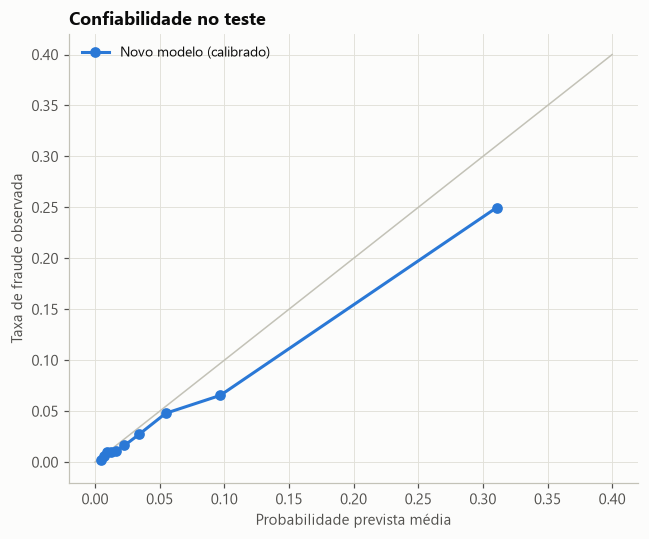

Prob. média prevista: 0.0568 | taxa real: 0.0446
Brier — bruto: 0.03453 | calibrado: 0.03494


In [9]:
faixa_p = pd.qcut(teste["p_modelo"], 10, duplicates="drop")
conf = teste.groupby(faixa_p, observed=True).agg(prevista=("p_modelo", "mean"), observada=("fraude", "mean"))
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 0.4], [0, 0.4], color=gr.EIXO, lw=1)
ax.plot(conf["prevista"], conf["observada"], marker="o", color=gr.AZUL, label="Novo modelo (calibrado)")
ax.set(title="Confiabilidade no teste", xlabel="Probabilidade prevista média", ylabel="Taxa de fraude observada")
ax.legend()
plt.tight_layout(); plt.show()
print(f"Prob. média prevista: {teste['p_modelo'].mean():.4f} | taxa real: {y.mean():.4f}")
print(f"Brier — bruto: {brier_score_loss(y, teste['p_bruta']):.5f} | calibrado: {brier_score_loss(y, teste['p_modelo']):.5f}")

O modelo **superestima levemente** o risco no teste (prob. média ~5,7% contra 4,5% real), porque herdou a
taxa base mais alta das janelas de calibração. 

No teste, o **Brier score** do calibrado chega a ser um pouco pior
que o do bruto (quanto menor, melhor). 

A **ordenação não é afetada**, mas um limiar fixo de
probabilidade bloquearia um pouco mais do que o ideal. 

Isso tem duas consequências práticas:
1. o ponto de corte deve ser **monitorado e reajustado** pela taxa de aprovação/fraude observada;
2. a calibração deve ser **reajustada com frequência** (é barata e não exige retreino).

## 7. Conclusão

| Métrica (teste OOT) | Score atual | Novo modelo | Ganho |
|---|---|---|---|
| ROC AUC | 0,726 | **0,851** | +17% |
| PR AUC | 0,227 | **0,368** | +62% |
| KS | 0,453 | **0,546** | +20% |
| Recall @ FPR 1% | 15,8% | **25,2%** | +60% |
| Recall @ FPR 5% | 41,8% | **47,8%** | +14% |
| Recall **R$** @ FPR 5% | 44,1% | **62,6%** | +42% |

**O novo modelo é claramente superior**, com significância estatística (IC 95% do ganho acima de zero),
consistência diária (vence em todos os dias) e ganho concentrado onde o atual é cego. 

O ROC AUC de teste (0,851) ficou **praticamente igual ao estimado na validação cruzada temporal**. 
O PR AUC caiu (0,42 → 0,37), mas isso é efeito da **menor prevalência** de fraude no teste (4,5% contra 5,7%).
- Apesar disso, em *lift* sobre o aleatório (PR AUC ÷ taxa de fraude), o teste (8,3x) é até melhor que o CV (7,5x). 
- Ou seja, **o laboratório foi um bom proxy do futuro**, com a ressalva da calibração sob mudança de taxa base.